In [4]:
#WEEK 3

  WEEK 3: UNSUPERVISED LEARNING & MODEL EVALUATION PIPELINE

--- 1. Quantitative Cluster Validation (K-Means) ---


C:\Users\ADMIN\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ADMIN\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\ADMIN\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ADMIN\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

k=2 | Inertia:  4204.52 | Silhouette Score: 0.3093 | Davies-Bouldin: 1.5636
k=3 | Inertia:  3297.30 | Silhouette Score: 0.3381 | Davies-Bouldin: 1.3323


C:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


k=4 | Inertia:  2774.63 | Silhouette Score: 0.3479 | Davies-Bouldin: 1.1806
k=5 | Inertia:  2361.38 | Silhouette Score: 0.3716 | Davies-Bouldin: 1.1846
k=6 | Inertia:  2048.38 | Silhouette Score: 0.3809 | Davies-Bouldin: 1.0791


C:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


k=7 | Inertia:  1799.79 | Silhouette Score: 0.3942 | Davies-Bouldin: 1.0941
k=8 | Inertia:  1644.77 | Silhouette Score: 0.3851 | Davies-Bouldin: 1.0708


C:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(



--- 2. PCA Dimensionality Reduction ---
PC1 Variance Explained: 29.94%
PC2 Variance Explained: 28.05%
Total Cumulative Variance: 57.98%

--- 3. Supervised Tuned Random Forest Results ---
Test Accuracy : 81.01%
Precision     : 0.8302
Recall        : 0.6377
F1-Score      : 0.7213
ROC-AUC       : 0.8475

Train Accuracy: 83.99% | Generalization Gap: 2.98%
5-Fold CV Mean: 82.94% (± 1.90%)



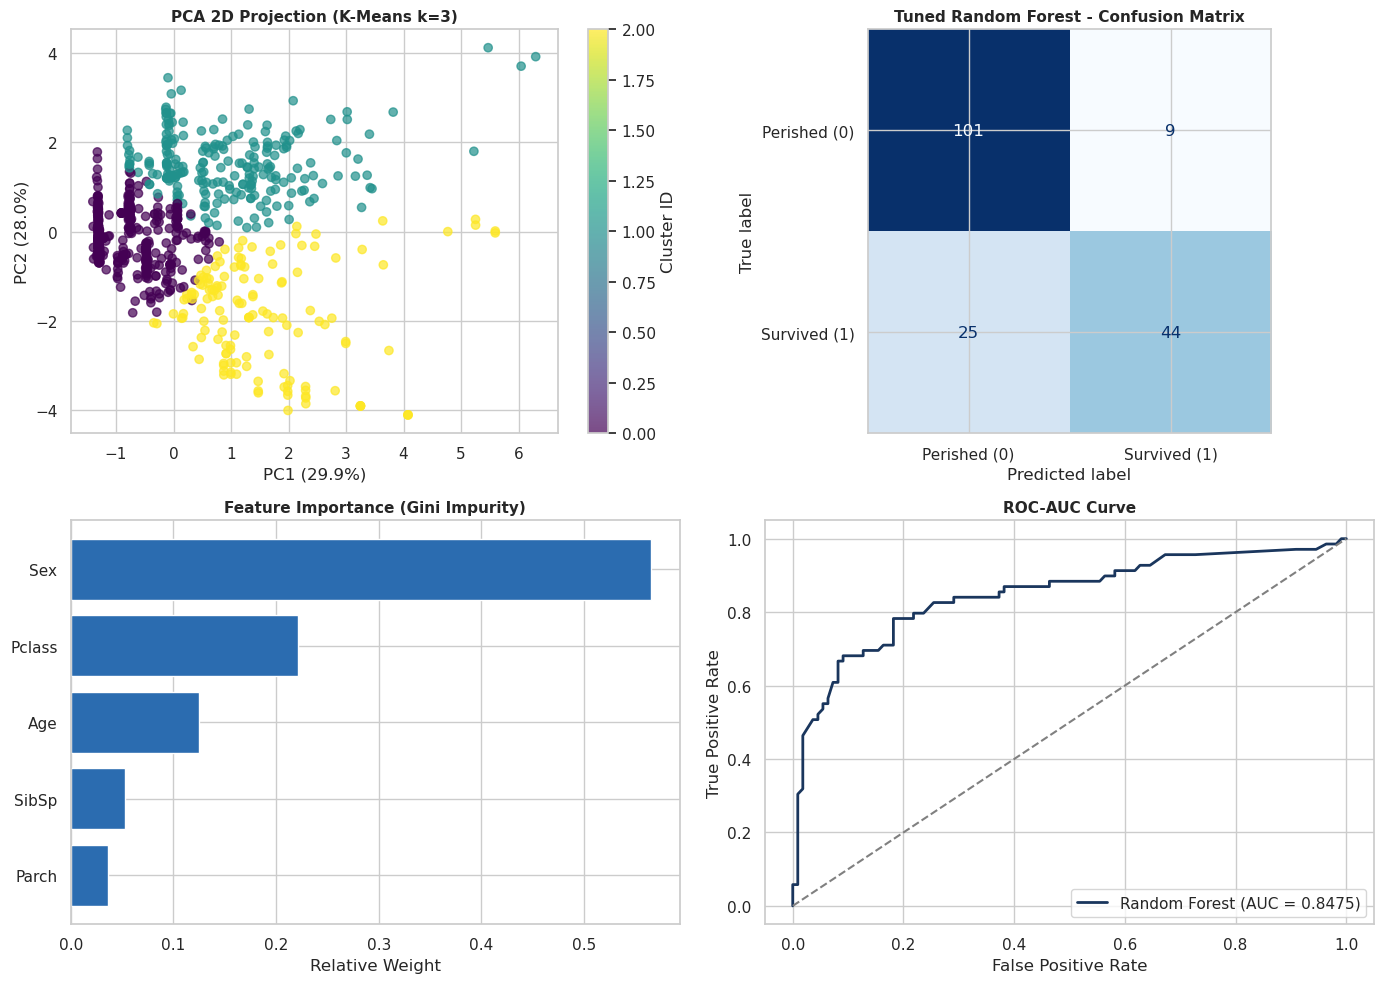

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

def run_week3_pipeline():
    print("=================================================================")
    print("  WEEK 3: UNSUPERVISED LEARNING & MODEL EVALUATION PIPELINE")
    print("=================================================================\n")
    
    # 1. LOAD DATASET
    df = pd.read_csv('cleaned_titanic.csv')
    
    # Separate numeric features for clustering
    X_num = df.select_dtypes(include=[np.number]).drop(columns=['Survived'], errors='ignore')
    
    # 2. FEATURE SCALING
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_num)
    
    # 3. K-MEANS CLUSTERING & QUANTITATIVE VALIDATION
    print("--- 1. Quantitative Cluster Validation (K-Means) ---")
    inertia_list = []
    silhouette_list = []
    db_list = []
    k_range = range(2, 9)
    
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_scaled)
        
        inertia = kmeans.inertia_
        sil = silhouette_score(X_scaled, labels)
        db = davies_bouldin_score(X_scaled, labels)
        
        inertia_list.append(inertia)
        silhouette_list.append(sil)
        db_list.append(db)
        print(f"k={k} | Inertia: {inertia:8.2f} | Silhouette Score: {sil:.4f} | Davies-Bouldin: {db:.4f}")
        
    # Fit Optimal K-Means (k=3)
    optimal_k = 3
    kmeans_opt = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
    cluster_labels_km = kmeans_opt.fit_predict(X_scaled)
    
    # 4. HIERARCHICAL CLUSTERING
    agg_clustering = AgglomerativeClustering(n_clusters=optimal_k, metric='euclidean', linkage='ward')
    cluster_labels_agg = agg_clustering.fit_predict(X_scaled)
    
    # 5. DIMENSIONALITY REDUCTION (PCA)
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    var_exp = pca.explained_variance_ratio_
    print(f"\n--- 2. PCA Dimensionality Reduction ---")
    print(f"PC1 Variance Explained: {var_exp[0]*100:.2f}%")
    print(f"PC2 Variance Explained: {var_exp[1]*100:.2f}%")
    print(f"Total Cumulative Variance: {sum(var_exp)*100:.2f}%\n")
    
    # 6. SUPERVISED MODEL TRAINING & EVALUATION
    X_cls = df.select_dtypes(include=[np.number]).drop(columns=['Survived', 'Fare'], errors='ignore')
    y_cls = df['Survived']
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
    )
    
    # Hyperparameter Tuning for Random Forest
    param_grid = {
        'n_estimators': [50, 100, 200],
        'max_depth': [4, 6, 8, 10],
        'min_samples_split': [2, 5, 10]
    }
    rf_base = RandomForestClassifier(random_state=42)
    grid = GridSearchCV(rf_base, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y_train)
    
    best_rf = grid.best_estimator_
    y_pred = best_rf.predict(X_test)
    y_prob = best_rf.predict_proba(X_test)[:, 1]
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc_val = roc_auc_score(y_test, y_prob)
    
    print("--- 3. Supervised Tuned Random Forest Results ---")
    print(f"Test Accuracy : {acc*100:.2f}%")
    print(f"Precision     : {prec:.4f}")
    print(f"Recall        : {rec:.4f}")
    print(f"F1-Score      : {f1:.4f}")
    print(f"ROC-AUC       : {roc_auc_val:.4f}\n")
    
    # Overfitting Check
    train_acc = accuracy_score(y_train, best_rf.predict(X_train))
    gap = (train_acc - acc) * 100
    print(f"Train Accuracy: {train_acc*100:.2f}% | Generalization Gap: {gap:.2f}%")
    
    # 5-Fold Stratified Cross-Validation
    cv_scores = cross_val_score(best_rf, X_cls, y_cls, cv=5, scoring='accuracy')
    print(f"5-Fold CV Mean: {cv_scores.mean()*100:.2f}% (± {cv_scores.std()*100:.2f}%)\n")
    
    # 7. DIAGNOSTIC VISUALIZATIONS
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Subplot 1: PCA 2D Scatter with K-Means Clusters
    scatter = axes[0, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels_km, cmap='viridis', alpha=0.7)
    axes[0, 0].set_title('PCA 2D Projection (K-Means k=3)', fontsize=11, fontweight='bold')
    axes[0, 0].set_xlabel(f'PC1 ({var_exp[0]*100:.1f}%)')
    axes[0, 0].set_ylabel(f'PC2 ({var_exp[1]*100:.1f}%)')
    fig.colorbar(scatter, ax=axes[0, 0], label='Cluster ID')
    
    # Subplot 2: Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Perished (0)', 'Survived (1)'])
    disp.plot(ax=axes[0, 1], cmap='Blues', colorbar=False)
    axes[0, 1].set_title('Tuned Random Forest - Confusion Matrix', fontsize=11, fontweight='bold')
    
    # Subplot 3: Feature Importances
    importances = best_rf.feature_importances_
    features = X_cls.columns
    feat_df = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values('Importance', ascending=True)
    axes[1, 0].barh(feat_df['Feature'], feat_df['Importance'], color='#2B6CB0')
    axes[1, 0].set_title('Feature Importance (Gini Impurity)', fontsize=11, fontweight='bold')
    axes[1, 0].set_xlabel('Relative Weight')
    
    # Subplot 4: ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[1, 1].plot(fpr, tpr, color='#1A365D', lw=2, label=f'Random Forest (AUC = {roc_auc_val:.4f})')
    axes[1, 1].plot([0, 1], [0, 1], color='gray', linestyle='--')
    axes[1, 1].set_title('ROC-AUC Curve', fontsize=11, fontweight='bold')
    axes[1, 1].set_xlabel('False Positive Rate')
    axes[1, 1].set_ylabel('True Positive Rate')
    axes[1, 1].legend(loc='lower right')
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    run_week3_pipeline()